# Discrete Mathematics: Grammars, Parsing and Computability

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and the previous notebook on automata, or a university student revising *Theory of Automata / Theory of Computation* (a core or elective course in BS CS, BS AI and BS Data Science programmes) for an exam or interview.
>
> **What you will learn**
> - **Context-free grammars (CFGs)**: rules, derivations, parse trees, and **ambiguity** (the arithmetic and dangling-else examples)
> - **Chomsky normal form (CNF)**: the conversion algorithm, written from scratch
> - The **CYK parser**: deciding whether a string belongs to any context-free language in $O(n^3)$
> - A **recursive-descent parser** and evaluator for arithmetic (with correct operator precedence) and for a JSON subset, tested against Python's own `eval` and `json`
> - **Pushdown automata (PDAs)**: a simulator, with machines for balanced brackets, $a^nb^n$ and palindromes
> - The **Chomsky hierarchy**: regular ⊂ context-free ⊂ context-sensitive ⊂ recursively enumerable
> - A **Turing machine simulator** running binary increment, a palindrome checker and the famous busy beavers
> - **Decidability**: the halting problem (the diagonal argument), **Rice's theorem**, and why a perfect bug detector or a perfect AI-safety verifier cannot exist
> - How all of this shows up in modern AI: **grammar-constrained LLM decoding**, tokenizers as automata, probabilistic grammars in NLP
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) (functions, dicts, recursion). Strongly recommended: [`04_automata_and_regular_languages.ipynb`](04_automata_and_regular_languages.ipynb) (DFAs, NFAs, regular expressions, the pumping lemma), because this notebook starts exactly where that one stops. Helpful: [`dsa/01_complexity_analysis_and_recursion.ipynb`](../../00_AI_Fundamentals/dsa/01_complexity_analysis_and_recursion.ipynb) (Big-O, recursion) and [`dsa/09_dynamic_programming.ipynb`](../../00_AI_Fundamentals/dsa/09_dynamic_programming.ipynb) (CYK is a dynamic program).
>
> **Time needed:** about 3 to 4 hours (reading, running, and the practice problems).
>
> **Runs on:** CPU, no API key, no internet. Libraries: Python standard library, numpy, pandas, matplotlib, networkx. The whole notebook runs in well under a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Sipser, *Introduction to the Theory of Computation* (3rd ed.), chapters 2 to 5 and 7, and Hopcroft, Motwani and Ullman, *Introduction to Automata Theory, Languages, and Computation* (3rd ed.), chapters 5 to 9.

## Explained simply

A **grammar** is a small set of rules that says which sentences are allowed, like the rules of a language or of a maths formula. A **parser** is a program that reads a sentence and checks it against those rules, building a tree that shows how the pieces fit together. Grammars can describe **nesting** (brackets inside brackets, folders inside folders), which simple pattern-matching cannot. At the top of the ladder sits the **Turing machine**, a model of every possible computer. The surprising part: there are questions, such as "will this program ever stop?", that **no** computer program can answer correctly for every case.

**Everyday examples**
- A calculator must read `2 + 3 × 4` as `2 + (3 × 4) = 14`, not `(2 + 3) × 4 = 20`. The grammar inside it decides that multiplication happens first.
- Checking brackets is like stacking plates: every `(` puts a plate on the pile and every `)` takes one off. If you try to take a plate from an empty pile, or plates are left at the end, the brackets are wrong.
- When a chatbot is forced to answer in valid JSON, a grammar checker sits next to it and blocks every word that would break the format.

**A tiny concrete example.** Rule: "a sentence is either empty, or `a` + sentence + `b`". Start with nothing, wrap once to get `ab`, wrap again to get `aabb`, again to get `aaabbb`. So `aaabbb` is allowed but `aabbb` is not: the rule always adds one `a` and one `b` together, so the counts must match.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Grammar and parser | Rules for allowed sentences, and a program that checks them | Calculators, compilers, JSON readers, LLM structured outputs |
| Pushdown automaton | A machine whose only memory is a stack of plates | Bracket checkers, HTML tag matching, code editors |
| Halting problem | No program can predict for every program whether it will stop | Why bug finders and AI-safety checkers can never be perfect |

### How this notebook is different from its neighbours
- [`04_automata_and_regular_languages.ipynb`](04_automata_and_regular_languages.ipynb) covers the *weakest* machines (finite automata) and regular expressions. Here we climb the ladder: grammars and stack machines (context-free), then Turing machines (everything computable), then the limits of computation itself.
- [`07_NLP/10_advanced_nlp_tasks.ipynb`](../../07_NLP/10_advanced_nlp_tasks.ipynb) uses the CKY algorithm to parse *English* with trained models. Here we build CYK from first principles, prove what it can and cannot do, and use it on formal languages.
- NP-completeness and reductions between hard *decidable* problems are covered in [`advanced_algorithms/02_np_completeness_and_reductions.ipynb`](../../00_AI_Fundamentals/advanced_algorithms/02_np_completeness_and_reductions.ipynb). This notebook covers problems that no algorithm can solve at all.

### Why an AI engineer needs this
- Every time an LLM is forced to output valid JSON, SQL or code, a **grammar** and a **pushdown automaton** are running inside the decoder.
- Every compiler, query engine, config loader and template language you use starts with a **parser**.
- The **halting problem** tells you, with mathematical certainty, what tools such as static analysers, AI code reviewers and safety verifiers can and cannot promise.

## Table of contents
1. Beyond regular languages: why we need grammars
2. Context-free grammars, derivations and parse trees
3. Ambiguity
4. Chomsky normal form
5. The CYK parser
6. Recursive-descent parsing and operator precedence
7. Pushdown automata
8. The Chomsky hierarchy
9. Turing machines
10. Decidability and the halting problem
11. Rice's theorem and what it means for tools
12. Complexity classes: a short recap
13. How this connects to modern AI
14. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)
rng = np.random.default_rng(42)   # the modern NumPy random generator

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import re, json, itertools
from functools import lru_cache
from collections import deque, defaultdict
import networkx as nx

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Beyond regular languages: why we need grammars

> **In plain English:** some patterns, like brackets inside brackets, need unlimited memory to check, so we need a stronger tool than regular expressions.

A quick reminder of the vocabulary from the automata notebook:
- An **alphabet** $\Sigma$ is a finite set of symbols, for example $\{a, b\}$ or the 128 ASCII characters.
- A **string** is a finite sequence of symbols. The empty string is written $\varepsilon$.
- A **language** is a set of strings, for example "all valid email addresses" or $\{a^nb^n : n \ge 0\} = \{\varepsilon, ab, aabb, aaabbb, \dots\}$.

A finite automaton has a fixed, finite memory (its current state). The **pumping lemma** shows that no finite automaton recognises $\{a^nb^n\}$: to check that the number of `b`s equals the number of `a`s it would have to *count without limit*, and a machine with $k$ states cannot tell $a^{k+1}$ apart from some shorter $a^j$.

The same problem appears everywhere in real data:
- balanced brackets in code, JSON and maths: `{"a": [1, [2, 3]]}`;
- matching `<div> … </div>` tags in HTML;
- nested `if … then … else` statements.

**Everyday analogy.** A regular expression is like a security guard with a clicker that can only count up to, say, 10. A context-free grammar is like a guard with a **stack of trays**: every time someone walks in with a tray, the guard puts one on the pile, and every time someone leaves, one comes off. The pile can grow as high as needed, so nesting can be arbitrarily deep.

So we need a more powerful description: the **context-free grammar**, and its matching machine, the **pushdown automaton** (a finite automaton plus a stack).

---
## 2. Context-free grammars, derivations and parse trees

> **In plain English:** a grammar is a list of replacement rules, and a parse tree is the family tree showing which rules built a sentence.

**Definition.** A **context-free grammar (CFG)** is a 4-tuple $G = (V, \Sigma, R, S)$ where
- $V$ is a finite set of **variables** (also called **non-terminals**), written in capitals: `S`, `E`, `T`;
- $\Sigma$ is a finite set of **terminals** (the alphabet of the language), disjoint from $V$;
- $R$ is a finite set of **rules** (productions) of the form $A \to \alpha$ with $A \in V$ and $\alpha \in (V \cup \Sigma)^*$, a string of variables and terminals (possibly empty, written $\varepsilon$);
- $S \in V$ is the **start variable**.

It is called *context-free* because a rule $A \to \alpha$ may be applied to $A$ wherever it appears, regardless of the symbols around it (its context).

**Derivations.** We write $uAv \Rightarrow u\alpha v$ when we replace one variable using the rule $A \to \alpha$, and $\Rightarrow^*$ for "zero or more steps". The **language of G** is

$$L(G) = \{ w \in \Sigma^* : S \Rightarrow^* w \}.$$

A language is **context-free (a CFL)** if some CFG generates it. A **leftmost derivation** always replaces the leftmost variable.

**Worked example by hand.** The grammar $S \to aSb \mid \varepsilon$ (the bar `|` means "or": two rules with the same left side) generates $\{a^nb^n\}$:

| Step | Sentential form | Rule used |
|---|---|---|
| 0 | `S` | start |
| 1 | `a S b` | $S \to aSb$ |
| 2 | `a a S b b` | $S \to aSb$ |
| 3 | `a a b b` | $S \to \varepsilon$ |

In Python we store a grammar as a dict that maps each variable to a list of right-hand sides; each right-hand side is a tuple of symbols, and `()` is $\varepsilon$. Any symbol that is not a key of the dict is a terminal.

In [2]:
# A grammar is {variable: [right-hand side, ...]}; each right-hand side is a tuple of symbols.
# () is the empty string epsilon. Any symbol that is not a key is a terminal.
G_anbn = {"S": [("a", "S", "b"), ()]}                       # S -> a S b | eps
G_paren = {"S": [("S", "S"), ("(", "S", ")"), ()]}          # S -> S S | ( S ) | eps   (balanced brackets)

def terminals_of(G):
    """All symbols on right-hand sides that are not variables."""
    return sorted({s for rhss in G.values() for rhs in rhss for s in rhs if s not in G})

def nullable_set(G):
    """Variables that can derive the empty string (fixed-point iteration)."""
    nullable, changed = set(), True
    while changed:                                          # keep going until nothing new is learned
        changed = False
        for A, rhss in G.items():
            if A not in nullable and any(all(s in nullable for s in rhs) for rhs in rhss):
                nullable.add(A)                             # every symbol of some rule is nullable
                changed = True
    return nullable

def generate(G, start, max_len, max_form=None):
    """Breadth-first search over leftmost derivations. Returns every string of
    length <= max_len that the search reaches (enough for small demos)."""
    max_form = max_form or 2 * max_len + 2                  # cap on sentential-form length
    nullable = nullable_set(G)
    seen, out = set(), set()
    queue = deque([(start,)])
    while queue:
        form = queue.popleft()
        idx = next((i for i, s in enumerate(form) if s in G), None)   # leftmost variable
        if idx is None:                                     # only terminals left: a sentence
            out.add("".join(form))
            continue
        for rhs in G[form[idx]]:                            # try every rule for that variable
            new = form[:idx] + rhs + form[idx + 1:]
            # each terminal and each non-nullable variable adds >= 1 symbol to the final string
            min_len = sum(1 for s in new if s not in G or s not in nullable)
            if min_len <= max_len and len(new) <= max_form and new not in seen:
                seen.add(new)
                queue.append(new)
    return sorted(out, key=lambda w: (len(w), w))

print("S -> aSb | eps     :", [w or "ε" for w in generate(G_anbn, "S", 8)])
print("S -> SS | (S) | eps:", [w or "ε" for w in generate(G_paren, "S", 6)])

S -> aSb | eps     : ['ε', 'ab', 'aabb', 'aaabbb', 'aaaabbbb']
S -> SS | (S) | eps: ['ε', '()', '(())', '()()', '((()))', '(()())', '(())()', '()(())', '()()()']


In [3]:
# Check the generated sets against simple "oracle" functions written directly in Python
def is_anbn(w):
    n = len(w) // 2
    return w == "a" * n + "b" * n

def is_balanced(w):
    depth = 0
    for ch in w:
        depth += 1 if ch == "(" else -1
        if depth < 0:                       # a ")" with nothing to close
            return False
    return depth == 0

def all_strings(alphabet, max_len):
    for n in range(max_len + 1):
        for t in itertools.product(alphabet, repeat=n):
            yield "".join(t)

assert set(generate(G_anbn, "S", 8)) == {w for w in all_strings("ab", 8) if is_anbn(w)}
assert set(generate(G_paren, "S", 8)) == {w for w in all_strings("()", 8) if is_balanced(w)}
print("Generated languages match the oracles for every string up to length 8.")
print("Number of balanced strings of length 0, 2, 4, 6, 8:",
      [sum(1 for w in generate(G_paren, "S", 8) if len(w) == n) for n in range(0, 9, 2)],
      "(the Catalan numbers)")

Generated languages match the oracles for every string up to length 8.


Number of balanced strings of length 0, 2, 4, 6, 8: [1, 1, 2, 5, 14] (the Catalan numbers)


**What just happened?** `generate` explored derivations breadth-first, like the uninformed search of [`classical_ai/02`](../../00_AI_Fundamentals/classical_ai/02_uninformed_search.ipynb), where a "state" is a sentential form and an "action" is applying a rule. The strings it found exactly match the hand-written checkers, and the counts of balanced strings (1, 1, 2, 5, 14) are the **Catalan numbers**, which also count binary trees (see [`02_combinatorics_and_recurrences.ipynb`](02_combinatorics_and_recurrences.ipynb)).

**Parse trees.** A **parse tree** (derivation tree) records *which* rule expanded each variable, without caring about the order of the steps. The root is the start variable, internal nodes are variables, leaves are terminals (or ε), and the children of a node $A$, read left to right, are the right-hand side of the rule used. Many derivations (leftmost, rightmost, mixed) can correspond to one tree, but each tree has exactly one *leftmost* derivation.

We now write a small parser that finds **all** parse trees of a token list for any grammar without ε-rules. It tries every rule and every way to split the input among the rule's symbols, and memoises the results (a top-down dynamic program). We will use it as a trusted "brute-force" checker throughout the notebook.

Leftmost derivation of aaabbb with S -> aSb | ab:
    S
    a S b
    a a S b b
    a a a b b b


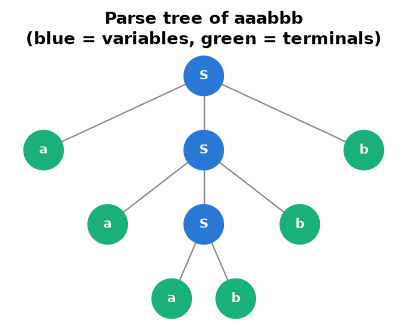

In [4]:
def all_parse_trees(G, start, tokens, match=None):
    """Return every parse tree of `tokens` (a list) from `start`.
    Works for grammars with no epsilon-rules and no cycles of unit rules (A -> B -> ... -> A).
    A tree is a tuple (variable, child1, child2, ...); a leaf is the token string itself."""
    match = match or (lambda terminal, tok: terminal == tok)     # how a terminal matches a token
    n = len(tokens)

    @lru_cache(maxsize=None)
    def trees_sym(X, i, j):                  # all trees deriving tokens[i:j] from symbol X
        if X not in G:                       # terminal: must match exactly one token
            return (tokens[i],) if j == i + 1 and match(X, tokens[i]) else ()
        out = []
        for rhs in G[X]:
            for kids in trees_seq(rhs, i, j):
                out.append((X,) + kids)
        return tuple(out)

    @lru_cache(maxsize=None)
    def trees_seq(rhs, i, j):                # all ways for the symbol sequence rhs to derive tokens[i:j]
        if not rhs:
            return ((),) if i == j else ()
        first, rest = rhs[0], rhs[1:]
        out = []
        for k in range(i + 1, j - len(rest) + 1):    # every symbol covers at least one token
            for t1 in trees_sym(first, i, k):
                for t2 in trees_seq(rest, k, j):
                    out.append((t1,) + t2)
        return tuple(out)

    return list(trees_sym(start, 0, n))

def leftmost_derivation(tree):
    """Turn a parse tree into its leftmost derivation (a list of sentential forms)."""
    label = lambda x: x[0] if isinstance(x, tuple) else x
    form, steps = [tree], [[label(tree)]]
    while any(isinstance(x, tuple) for x in form):
        i = next(i for i, x in enumerate(form) if isinstance(x, tuple))   # leftmost variable
        form = form[:i] + list(form[i][1:]) + form[i + 1:]                # replace it by its children
        steps.append([label(x) for x in form])
    return [" ".join(s) for s in steps]

def tree_positions(tree):
    """Layout: leaves get x = 0, 1, 2, ...; a parent sits above the mean of its children."""
    G_draw, pos, labels, counter = nx.DiGraph(), {}, {}, [0]
    def walk(node, depth):
        nid = len(labels)
        labels[nid] = node[0] if isinstance(node, tuple) else node
        G_draw.add_node(nid)
        if isinstance(node, tuple) and len(node) > 1:
            xs = []
            for child in node[1:]:
                cid = walk(child, depth + 1)
                G_draw.add_edge(nid, cid)
                xs.append(pos[cid][0])
            pos[nid] = (sum(xs) / len(xs), -depth)
        else:
            pos[nid] = (counter[0], -depth)
            counter[0] += 1
        return nid
    walk(tree, 0)
    return G_draw, pos, labels

def draw_tree(tree, ax, title=""):
    G_draw, pos, labels = tree_positions(tree)
    is_var = {n: (labels[n][:1].isupper()) for n in G_draw}
    colors = [PALETTE[0] if is_var[n] else PALETTE[2] for n in G_draw]
    nx.draw(G_draw, pos, ax=ax, labels=labels, node_color=colors, node_size=800, font_size=9,
            font_color="white", font_weight="bold", arrows=False, edge_color="#888888")
    ax.set_title(title)

tree = all_parse_trees(G_anbn | {"S": [("a", "S", "b"), ("a", "b")]}, "S", list("aaabbb"))[0]
print("Leftmost derivation of aaabbb with S -> aSb | ab:")
for step in leftmost_derivation(tree):
    print("   ", step)
fig, ax = plt.subplots(figsize=(5, 3.5))
draw_tree(tree, ax, "Parse tree of aaabbb\n(blue = variables, green = terminals)")
plt.show()

**What just happened?** We used the ε-free grammar $S \to aSb \mid ab$ (it generates $a^nb^n$ for $n \ge 1$), found the single parse tree of `aaabbb`, and replayed it as a leftmost derivation. The tree's height grows with $n$: this nesting is exactly what a finite automaton cannot track.

**Complexity of the brute-force parser.** There are $O(n^2)$ spans $(i, j)$, and for each span and rule we try $O(n^{k-1})$ split points for a rule with $k$ symbols, so counting trees costs polynomial time. *Listing* all trees can be exponential, because the number of trees itself can be exponential (see the next section).

---
## 3. Ambiguity

> **In plain English:** a grammar is ambiguous when one sentence can be built in two different ways, which can give it two different meanings.

**Definition.** A grammar is **ambiguous** if some string in its language has **two or more different parse trees** (equivalently, two different leftmost derivations). A context-free *language* is **inherently ambiguous** if *every* grammar for it is ambiguous; a classic example is $\{a^ib^jc^k : i = j \text{ or } j = k\}$.

Ambiguity matters because the tree is the *meaning*. Consider the grammar

$$E \to E + E \mid E * E \mid ( E ) \mid \text{num}$$

and the input `2 + 3 * 4`. One tree groups `(2 + 3) * 4 = 20`, the other `2 + (3 * 4) = 14`. A calculator that picks the wrong tree gives the wrong answer.

'2 + 3 * 4' has 2 parse trees under the ambiguous grammar


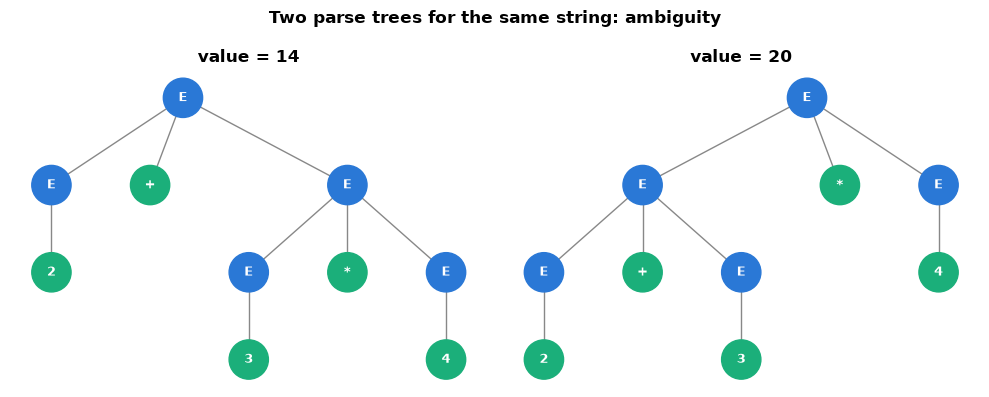

In [5]:
G_amb = {"E": [("E", "+", "E"), ("E", "*", "E"), ("(", "E", ")"), ("num",)]}
num_match = lambda terminal, tok: terminal == tok or (terminal == "num" and tok.isdigit())

def evaluate_tree(t):
    """Evaluate an arithmetic parse tree bottom-up."""
    if not isinstance(t, tuple):
        return int(t)
    kids = t[1:]
    if len(kids) == 1:
        return evaluate_tree(kids[0])
    if kids[0] == "(":
        return evaluate_tree(kids[1])
    a, op, b = evaluate_tree(kids[0]), kids[1], evaluate_tree(kids[2])
    return a + b if op == "+" else a * b

tokens = "2 + 3 * 4".split()
trees = all_parse_trees(G_amb, "E", tokens, match=num_match)
print(f"'{' '.join(tokens)}' has {len(trees)} parse trees under the ambiguous grammar")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, t in zip(axes, trees):
    draw_tree(t, ax, f"value = {evaluate_tree(t)}")
plt.suptitle("Two parse trees for the same string: ambiguity", fontweight="bold")
plt.tight_layout(); plt.show()

In [6]:
# How fast does ambiguity grow? Count trees of  1 + 1 + ... + 1  with k plus signs.
counts = []
for k in range(1, 9):
    toks = ["1"] + ["+", "1"] * k
    counts.append(len(all_parse_trees(G_amb, "E", toks, match=num_match)))
print("plus signs :", list(range(1, 9)))
print("parse trees:", counts)
catalan = [math.comb(2 * k, k) // (k + 1) for k in range(1, 9)]
assert counts == catalan
print("These are the Catalan numbers C_k = (2k choose k)/(k+1): exponential growth (about 4^k).")

plus signs : [1, 2, 3, 4, 5, 6, 7, 8]
parse trees: [1, 2, 5, 14, 42, 132, 429, 1430]
These are the Catalan numbers C_k = (2k choose k)/(k+1): exponential growth (about 4^k).


**Removing the ambiguity.** The standard fix encodes precedence and associativity in *layers* of variables: an expression is a sum of **terms**, a term is a product of **factors**, and a factor is a number or a bracketed expression.

$$
\begin{aligned}
E &\to E + T \mid T \\
T &\to T * F \mid F \\
F &\to ( E ) \mid \text{num}
\end{aligned}
$$

Because `*` can only appear *inside* a `T`, it binds tighter than `+`. Because the recursion is on the *left* ($E \to E + T$), `1 + 2 + 3` groups as `(1 + 2) + 3`: **left associativity**.

**The dangling else.** In $S \to \texttt{if } c \texttt{ then } S \mid \texttt{if } c \texttt{ then } S \texttt{ else } S \mid x$, the string `if c then if c then x else x` has two trees: the `else` can belong to either `if`. C, Java and Python's ancestors all resolve it the same way: **the `else` matches the nearest unmatched `if`**. A grammar can enforce that rule with "matched" (M) and "unmatched" (U) statements.

In [7]:
G_expr = {"E": [("E", "+", "T"), ("T",)],
          "T": [("T", "*", "F"), ("F",)],
          "F": [("(", "E", ")"), ("num",)]}
for s in ["2 + 3 * 4", "1 + 1 + 1 + 1 + 1", "( 2 + 3 ) * 4"]:
    ts = all_parse_trees(G_expr, "E", s.split(), match=num_match)
    print(f"{s:20s} -> {len(ts)} tree(s), value = {evaluate_tree(ts[0])} (Python says {eval(s)})")

# Dangling else: ambiguous grammar vs the matched/unmatched fix
G_if = {"S": [("if", "c", "then", "S"), ("if", "c", "then", "S", "else", "S"), ("x",)]}
G_if_fixed = {"S": [("M",), ("U",)],
              "M": [("if", "c", "then", "M", "else", "M"), ("x",)],
              "U": [("if", "c", "then", "S"), ("if", "c", "then", "M", "else", "U")]}
toks = "if c then if c then x else x".split()
print("\nDangling else:", " ".join(toks))
print("  ambiguous grammar :", len(all_parse_trees(G_if, "S", toks)), "trees")
print("  matched/unmatched :", len(all_parse_trees(G_if_fixed, "S", toks)), "tree")

2 + 3 * 4            -> 1 tree(s), value = 14 (Python says 14)
1 + 1 + 1 + 1 + 1    -> 1 tree(s), value = 5 (Python says 5)
( 2 + 3 ) * 4        -> 1 tree(s), value = 20 (Python says 20)

Dangling else: if c then if c then x else x
  ambiguous grammar : 2 trees
  matched/unmatched : 1 tree


**What just happened?** The layered grammar gives exactly one tree for each expression, and the value agrees with Python's own operator precedence. The dangling-else string has 2 trees under the naive grammar and 1 under the fixed one, in which the `else` attaches to the inner `if`.

> ⚠️ **Common mistake.** "Ambiguous grammar" and "ambiguous language" are different things. $E \to E+E \mid E*E \mid (E) \mid \text{num}$ is ambiguous, but the *language* is not: we just wrote an unambiguous grammar for it. Also, there is **no algorithm** that decides whether an arbitrary CFG is ambiguous (the problem is undecidable, by a reduction from Post's correspondence problem), so tools such as parser generators report *conflicts* instead.

> 🎓 **Exam / interview tip.** To prove a grammar ambiguous, show **one string with two parse trees** (or two leftmost derivations). To fix expression ambiguity, introduce one variable per precedence level; left recursion gives left associativity, right recursion gives right associativity (used for `^`, exponentiation).

---
## 4. Chomsky normal form

> **In plain English:** we rewrite any grammar so every rule has one of two tiny shapes, which makes parsing algorithms simple.

Many algorithms (CYK, proofs of the pumping lemma for CFLs) are simpler if every rule has a fixed shape.

**Definition.** A CFG is in **Chomsky normal form (CNF)** if every rule is either
- $A \to BC$ (exactly two variables, neither of them the start variable), or
- $A \to a$ (exactly one terminal),
- plus, optionally, $S \to \varepsilon$ for the start variable only.

**Theorem.** Every CFG can be converted to an equivalent grammar in CNF (Sipser, Theorem 2.9). The conversion has five steps:

| Step | Name | What it does | Example |
|---|---|---|---|
| 1 | START | Add a new start $S_0 \to S$ so the start never appears on a right side | $S_0 \to S$ |
| 2 | TERM | In rules with 2+ symbols, replace each terminal $a$ by a new variable $T_a \to a$ | $S \to aSb$ becomes $S \to T_a S T_b$ |
| 3 | BIN | Split long rules into chains of length 2 | $S \to T_a S T_b$ becomes $S \to T_a X_1,\ X_1 \to S T_b$ |
| 4 | DEL | Remove ε-rules: for every rule, add copies with nullable variables left out | $X_1 \to S T_b$ adds $X_1 \to T_b$ |
| 5 | UNIT | Remove unit rules $A \to B$ by copying $B$'s rules into $A$ | $S_0 \to S$ becomes $S_0 \to T_a X_1 \mid \dots$ |

Doing DEL and UNIT *after* BIN keeps the grammar small: in the worst case the CNF grammar has $O(|G|^2)$ rules, whereas doing DEL first can cause an exponential blow-up.

In [8]:
def to_cnf(G, start):
    """Convert grammar G (start variable `start`) to Chomsky normal form.
    Returns (new_grammar, new_start). Steps: START, TERM, BIN, DEL, UNIT, then clean-up."""
    G = {A: [tuple(r) for r in rhss] for A, rhss in G.items()}    # copy
    fresh = itertools.count(1)

    # 1. START: a new start variable that never appears on a right-hand side
    S0 = start + "0"
    G[S0] = [(start,)]

    # 2. TERM: terminals inside rules of length >= 2 get their own variable T_a -> a
    term_var = {}
    for A in list(G):
        new_rules = []
        for rhs in G[A]:
            if len(rhs) >= 2:
                rhs = tuple(term_var.setdefault(s, f"T_{s}") if s not in G and not s.startswith("T_") else s
                            for s in rhs)
            new_rules.append(rhs)
        G[A] = new_rules
    for a, T in term_var.items():
        G[T] = [(a,)]

    # 3. BIN: A -> X1 X2 ... Xk (k > 2) becomes A -> X1 Y1, Y1 -> X2 Y2, ..., Y_{k-2} -> X_{k-1} Xk
    for A in list(G):
        new_rules = []
        for rhs in G[A]:
            left = A
            while len(rhs) > 2:
                Y = f"X{next(fresh)}"
                G.setdefault(Y, [])
                if left == A:
                    new_rules.append((rhs[0], Y))
                else:
                    G[left].append((rhs[0], Y))
                left, rhs = Y, rhs[1:]
            if left == A:
                new_rules.append(rhs)
            else:
                G[left].append(rhs)
        G[A] = new_rules

    # 4. DEL: remove epsilon-rules (keep S0 -> eps if the language contains eps)
    nullable = nullable_set(G)
    for A in G:
        new_rules = set()
        for rhs in G[A]:
            # every subset of nullable positions may be dropped
            options = [((s,), ()) if s in nullable else ((s,),) for s in rhs]
            for choice in itertools.product(*options):
                new_rhs = tuple(s for part in choice for s in part)
                if new_rhs or A == S0:
                    new_rules.add(new_rhs)
        G[A] = sorted(new_rules)

    # 5. UNIT: remove A -> B by copying B's non-unit rules into A (via the closure of unit pairs)
    is_unit = lambda rhs: len(rhs) == 1 and rhs[0] in G
    unit_pairs = {A: {A} for A in G}
    changed = True
    while changed:
        changed = False
        for A in G:
            for B in list(unit_pairs[A]):
                for rhs in G[B]:
                    if is_unit(rhs) and rhs[0] not in unit_pairs[A]:
                        unit_pairs[A].add(rhs[0]); changed = True
    G = {A: sorted({rhs for B in unit_pairs[A] for rhs in G[B] if not is_unit(rhs)}) for A in G}

    # Clean-up: drop variables that generate nothing or cannot be reached from S0
    generating, changed = set(), True
    while changed:
        changed = False
        for A, rhss in G.items():
            if A not in generating and any(all(s in generating or s not in G for s in r) for r in rhss):
                generating.add(A); changed = True
    G = {A: [r for r in rhss if all(s in generating or s not in G for s in r)]
         for A, rhss in G.items() if A in generating}
    reachable, stack = {S0}, [S0]
    while stack:
        for r in G.get(stack.pop(), []):
            for s in r:
                if s in G and s not in reachable:
                    reachable.add(s); stack.append(s)
    return {A: G[A] for A in G if A in reachable}, S0

def is_cnf(G, start):
    for A, rhss in G.items():
        for r in rhss:
            ok = (len(r) == 2 and all(s in G and s != start for s in r)) or \
                 (len(r) == 1 and r[0] not in G) or (r == () and A == start)
            if not ok:
                return False
    return True

def show_grammar(G):
    for A, rhss in G.items():
        print(f"   {A:4s} -> " + " | ".join(" ".join(r) if r else "ε" for r in rhss))

cnf_anbn, s_anbn = to_cnf(G_anbn, "S")
print("S -> aSb | eps  in Chomsky normal form:")
show_grammar(cnf_anbn)
print("is CNF:", is_cnf(cnf_anbn, s_anbn))

S -> aSb | eps  in Chomsky normal form:
   S    -> T_a X1
   S0   -> ε | T_a X1
   T_a  -> a
   T_b  -> b
   X1   -> S T_b | b
is CNF: True


**What just happened?** Read the output against the table above:
- $S_0 \to \varepsilon$ survives because ε is in the language.
- $S \to T_a X_1$ and $X_1 \to S T_b$ came from $S \to aSb$ via TERM ($a \to T_a$, $b \to T_b$) and BIN (the helper $X_1$).
- $X_1 \to b$ is the trace of DEL and UNIT: because $S$ is nullable, DEL added $X_1 \to T_b$ (the string "ab" with the inner $S$ left out), and UNIT then replaced that unit rule by $T_b$'s own rule, $b$.
- $S_0 \to T_a X_1$ is UNIT again: the unit rule $S_0 \to S$ was replaced by a copy of $S$'s rules.

Each step preserves the language, and we check that next by brute force against the oracles.

---
## 5. The CYK parser

> **In plain English:** CYK checks whether a sentence fits a grammar by solving small pieces first and combining them, like filling in a table.

The **Cocke–Younger–Kasami (CYK)** algorithm decides membership $w \in L(G)$ for a grammar in CNF. It is **dynamic programming** over substrings (compare the interval DP in [`dsa/09`](../../00_AI_Fundamentals/dsa/09_dynamic_programming.ipynb)).

**Idea.** Let $T[i][\ell]$ be the set of variables that derive the substring of length $\ell$ starting at position $i$.
- **Length 1:** $A \in T[i][1]$ iff $A \to w_i$ is a rule.
- **Length $\ell > 1$:** $A \in T[i][\ell]$ iff there is a rule $A \to BC$ and a split $1 \le k < \ell$ with $B \in T[i][k]$ and $C \in T[i+k][\ell-k]$.
- **Answer:** $w \in L(G)$ iff $S \in T[0][n]$.

CNF is what makes this work: every rule either produces one terminal or splits a span into exactly two smaller spans.

**Complexity.** There are $O(n^2)$ cells, each tries $O(n)$ split points and $|R|$ rules: **time $O(n^3 \cdot |R|)$, space $O(n^2 \cdot |V|)$**. (Valiant showed in 1975 that CFG parsing reduces to Boolean matrix multiplication, giving $O(n^{\omega})$ with $\omega < 2.372$, but the constants make it impractical.)

In [9]:
def cyk(G, start, w, return_table=False):
    """CYK membership test for a grammar in CNF. w is a string or list of tokens."""
    n = len(w)
    if n == 0:
        return () in G.get(start, [])
    T = [[set() for _ in range(n + 1)] for _ in range(n)]      # T[i][l]: variables deriving w[i:i+l]
    back = {}                                                  # back-pointers to rebuild a tree
    for i, a in enumerate(w):                                  # length-1 spans
        for A, rhss in G.items():
            if (a,) in rhss:
                T[i][1].add(A); back[(i, 1, A)] = a
    for l in range(2, n + 1):                                  # span length
        for i in range(n - l + 1):                             # span start
            for k in range(1, l):                              # split point
                left, right = T[i][k], T[i + k][l - k]
                if not left or not right:
                    continue
                for A, rhss in G.items():
                    for r in rhss:
                        if len(r) == 2 and r[0] in left and r[1] in right:
                            if A not in T[i][l]:
                                T[i][l].add(A); back[(i, l, A)] = (k, r[0], r[1])
    ok = start in T[0][n]
    return (ok, T, back) if return_table else ok

def cyk_tree(back, i, l, A):
    """Rebuild one parse tree from the CYK back-pointers."""
    b = back[(i, l, A)]
    if isinstance(b, str):
        return (A, b)
    k, B, C = b
    return (A, cyk_tree(back, i, k, B), cyk_tree(back, i + k, l - k, C))

# Show the CYK table for the word aabb
w = "aabb"
ok, T, back = cyk(cnf_anbn, s_anbn, w, return_table=True)
table = pd.DataFrame([[", ".join(sorted(T[i][l])) if i + l <= len(w) else ""
                       for i in range(len(w))] for l in range(1, len(w) + 1)],
                     index=[f"length {l}" for l in range(1, len(w) + 1)],
                     columns=[f"start {i} ({w[i]})" for i in range(len(w))])
print(f"Is '{w}' in a^n b^n?  {ok}")
table

Is 'aabb' in a^n b^n?  True


,start 0 (a),start 1 (a),start 2 (b),start 3 (b)
length 1,T_a,T_a,"T_b, X1","T_b, X1"
length 2,,"S, S0",,
length 3,,X1,,
length 4,"S, S0",,,


In [10]:
# Verify CYK + to_cnf against the oracles on EVERY string up to length 10
cnf_paren, s_paren = to_cnf(G_paren, "S")
print("Balanced brackets in CNF:"); show_grammar(cnf_paren)
for G_cnf, s, alphabet, oracle in [(cnf_anbn, s_anbn, "ab", is_anbn),
                                   (cnf_paren, s_paren, "()", is_balanced)]:
    words = list(all_strings(alphabet, 10))
    assert all(cyk(G_cnf, s, x) == oracle(x) for x in words)
    print(f"  CYK agrees with the oracle on all {len(words)} strings over {alphabet!r} up to length 10")

# The (unambiguous) expression grammar: CYK vs the brute-force parser on random token strings
cnf_expr, s_expr = to_cnf({k: [tuple("n" if s == "num" else s for s in r) for r in v]
                           for k, v in G_expr.items()}, "E")
print("\nExpression grammar in CNF has", sum(len(v) for v in cnf_expr.values()), "rules,",
      "is CNF:", is_cnf(cnf_expr, s_expr))
G_expr_n = {k: [tuple("n" if s == "num" else s for s in r) for r in v] for k, v in G_expr.items()}
agree = 0
for _ in range(400):
    toks = random.choices(["n", "+", "*", "(", ")"], k=random.randint(1, 9))
    expected = len(all_parse_trees(G_expr_n, "E", toks)) > 0
    assert cyk(cnf_expr, s_expr, toks) == expected
    agree += 1
print(f"CYK agrees with the brute-force parser on {agree} random token strings")

Balanced brackets in CNF:
   S    -> S S | T_( X1
   S0   -> ε | S S | T_( X1
   T_(  -> (
   T_)  -> )
   X1   -> ) | S T_)


  CYK agrees with the oracle on all 2047 strings over 'ab' up to length 10


  CYK agrees with the oracle on all 2047 strings over '()' up to length 10

Expression grammar in CNF has 20 rules, is CNF: True
CYK agrees with the brute-force parser on 400 random token strings


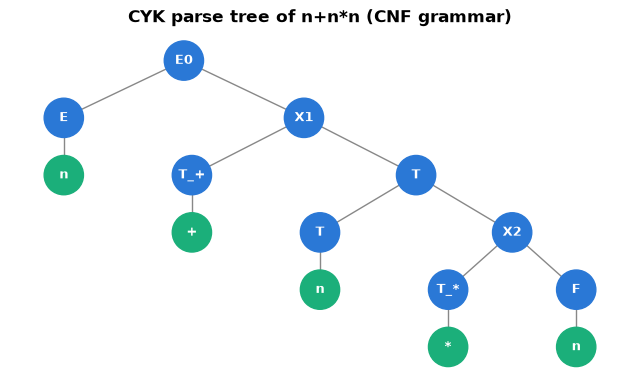

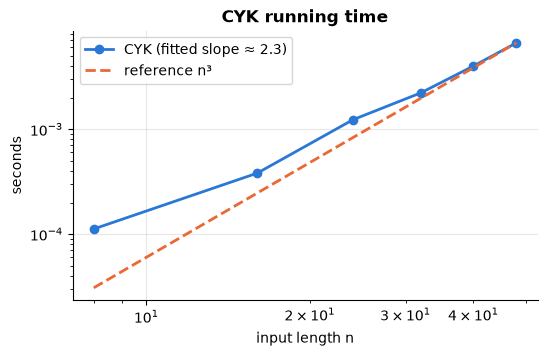

fitted log-log slope = 2.30 (theory: 3; small n and Python overhead blur it a little)


In [11]:
ok, T, back = cyk(cnf_expr, s_expr, list("n+n*n"), return_table=True)
fig, ax = plt.subplots(figsize=(8, 4.5))
draw_tree(cyk_tree(back, 0, 5, s_expr), ax, "CYK parse tree of n+n*n (CNF grammar)")
plt.show()

# Empirical running time: should grow roughly like n^3
lengths, times = [8, 16, 24, 32, 40, 48], []
for n in lengths:
    word = "()" * (n // 2)
    t0 = time.perf_counter(); assert cyk(cnf_paren, s_paren, word); times.append(time.perf_counter() - t0)
slope = np.polyfit(np.log(lengths), np.log(times), 1)[0]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(lengths, times, "o-", label=f"CYK (fitted slope ≈ {slope:.1f})")
ax.loglog(lengths, times[-1] * (np.array(lengths) / lengths[-1]) ** 3, "--", label="reference n³")
ax.set_xlabel("input length n"); ax.set_ylabel("seconds"); ax.set_title("CYK running time")
ax.legend(); plt.show()
print(f"fitted log-log slope = {slope:.2f} (theory: 3; small n and Python overhead blur it a little)")

**What just happened?**
- The bottom-left cell of the table (start 0, length 4) contains the CNF start variable, so `aabb` is accepted.
- Over 4,000 exhaustive strings plus 400 random token lists, CYK on the converted grammars agrees with independent checkers. This confirms both `to_cnf` and `cyk`.
- The parse tree of `n+n*n` is in binary form; the extra variables (`X1`, `T_+` …) are artefacts of CNF and are usually collapsed back afterwards.
- The running time grows polynomially; the printed slope is the empirical exponent.

> 🎓 **Exam / interview tip.** Fill a CYK table by hand **bottom row first** (length 1), then length 2, and so on. Each cell looks at pairs of cells below it: (length $k$ at $i$) with (length $\ell-k$ at $i+k$). Examiners usually ask for a 4- or 5-symbol word.

> ⚠️ **Common mistake.** Running CYK on a grammar that is *not* in CNF. Unit rules and ε-rules break the "split into exactly two pieces" logic, so you silently miss parses.

---
## 6. Recursive-descent parsing and operator precedence

> **In plain English:** a fast parser has one function per grammar rule, and the layering of those functions decides that `*` happens before `+`.

CYK handles *any* CFG, but cubic time is too slow for a compiler reading a million-line program. Real parsers use grammars designed so that the next token tells you which rule to apply. The simplest such parser is **recursive descent**: one function per variable, each function calls the functions of the variables on its right-hand side. For an **LL(1)** grammar (one token of lookahead decides the rule) it runs in **$O(n)$ time**.

**The left-recursion trap.** $E \to E + T$ would translate into `def parse_E(): parse_E(); ...`, which calls itself forever without consuming input. The standard fix rewrites left recursion as a loop, using EBNF repetition `{ }`:

```
expr    := term   { ("+" | "-") term }          lowest precedence, left-associative
term    := unary  { ("*" | "/") unary }
unary   := "-" unary | power                    unary minus
power   := atom [ "^" unary ]                   highest, RIGHT-associative: 2^3^2 = 2^(3^2)
atom    := NUMBER | "(" expr ")"
```

This mirrors Python's own grammar, in which `-2**2 == -4` (exponent binds tighter than unary minus) and `2**3**2 == 512`.

**Operator precedence table** (higher row binds tighter):

| Level | Operators | Associativity | Grammar variable |
|---|---|---|---|
| 4 | `^` | right | `power` |
| 3 | unary `-` | prefix | `unary` |
| 2 | `*` `/` | left | `term` |
| 1 | `+` `-` | left | `expr` |

A parser does two jobs: the **lexer** (tokenizer) turns characters into tokens with a regular expression (a DFA, from the previous notebook), and the **parser** builds an **abstract syntax tree (AST)** from the tokens.

In [12]:
TOKEN_RE = re.compile(r"\s*(?:(\d+(?:\.\d+)?)|(.))")      # a number, or any single character

def tokenize(text):
    tokens = []
    for number, op in TOKEN_RE.findall(text):
        if number:
            tokens.append(("NUM", float(number)))
        elif op.strip():
            tokens.append(("OP", op))
    return tokens + [("EOF", None)]

class ExprParser:
    """Recursive-descent parser: one method per grammar variable. Builds an AST of tuples."""
    def __init__(self, text):
        self.toks, self.i = tokenize(text), 0

    def peek(self):
        return self.toks[self.i]

    def eat(self, value=None):
        kind, v = self.toks[self.i]
        if value is not None and v != value:
            raise SyntaxError(f"expected {value!r} at token {self.i}, found {v!r}")
        self.i += 1
        return v

    def parse(self):
        tree = self.expr()
        if self.peek()[0] != "EOF":
            raise SyntaxError(f"unexpected {self.peek()[1]!r} at token {self.i}")
        return tree

    def expr(self):                       # expr := term { (+|-) term }
        node = self.term()
        while self.peek()[1] in ("+", "-"):
            op = self.eat()
            node = (op, node, self.term())        # building leftwards = left associativity
        return node

    def term(self):                       # term := unary { (*|/) unary }
        node = self.unary()
        while self.peek()[1] in ("*", "/"):
            op = self.eat()
            node = (op, node, self.unary())
        return node

    def unary(self):                      # unary := "-" unary | power
        if self.peek()[1] == "-":
            self.eat("-")
            return ("neg", self.unary())
        return self.power()

    def power(self):                      # power := atom [ "^" unary ]
        base = self.atom()
        if self.peek()[1] == "^":
            self.eat("^")
            return ("^", base, self.unary())      # recursion on the right = right associativity
        return base

    def atom(self):                       # atom := NUMBER | "(" expr ")"
        kind, v = self.peek()
        if kind == "NUM":
            self.eat(); return ("num", v)
        if v == "(":
            self.eat("("); node = self.expr(); self.eat(")"); return node
        raise SyntaxError(f"unexpected {'end of input' if kind == 'EOF' else repr(v)} at token {self.i}")

def evaluate(node):
    """Walk the AST and compute its value."""
    tag = node[0]
    if tag == "num": return node[1]
    if tag == "neg": return -evaluate(node[1])
    a, b = evaluate(node[1]), evaluate(node[2])
    if tag == "+": return a + b
    if tag == "-": return a - b
    if tag == "*": return a * b
    if tag == "/": return a / b          # raises ZeroDivisionError, like Python
    return a ** b                        # tag == "^"

for s in ["2 + 3 * 4", "(2 + 3) * 4", "10 - 4 - 3", "2 ^ 3 ^ 2", "-2 ^ 2", "8 / 4 / 2"]:
    ast = ExprParser(s).parse()
    print(f"{s:12s} = {evaluate(ast):6g}    AST: {ast}")

2 + 3 * 4    =     14    AST: ('+', ('num', 2.0), ('*', ('num', 3.0), ('num', 4.0)))
(2 + 3) * 4  =     20    AST: ('*', ('+', ('num', 2.0), ('num', 3.0)), ('num', 4.0))
10 - 4 - 3   =      3    AST: ('-', ('-', ('num', 10.0), ('num', 4.0)), ('num', 3.0))
2 ^ 3 ^ 2    =    512    AST: ('^', ('num', 2.0), ('^', ('num', 3.0), ('num', 2.0)))
-2 ^ 2       =     -4    AST: ('neg', ('^', ('num', 2.0), ('num', 2.0)))
8 / 4 / 2    =      1    AST: ('/', ('/', ('num', 8.0), ('num', 4.0)), ('num', 2.0))


In [13]:
# Test against Python's own parser on 2,000 random expressions
def random_expr(depth=0):
    r = random.random()
    if depth > 3 or r < 0.3:
        return str(random.randint(0, 9))
    if r < 0.4:
        return "(" + random_expr(depth + 1) + ")"
    if r < 0.5:
        return "-" + random_expr(depth + 1)
    if r < 0.58:
        return random_expr(depth + 1) + " ^ " + str(random.randint(0, 3))   # small exponents only
    return random_expr(depth + 1) + " " + random.choice("+-*/") + " " + random_expr(depth + 1)

checked = zero_div = 0
for _ in range(2000):
    s = random_expr()
    try:
        expected = eval(s.replace("^", "**"))
    except ZeroDivisionError:
        try:
            evaluate(ExprParser(s).parse()); raise AssertionError("should have divided by zero")
        except ZeroDivisionError:
            zero_div += 1; continue
    got = evaluate(ExprParser(s).parse())
    assert math.isclose(got, expected, rel_tol=1e-9, abs_tol=1e-9), (s, got, expected)
    checked += 1
print(f"Matches Python on {checked} random expressions ({zero_div} divided by zero in both)")
print("Example:", random_expr())

for bad in ["2 +", "(1 + 2", "3 4", "* 5"]:
    try:
        ExprParser(bad).parse()
    except SyntaxError as e:
        print(f"{bad!r:10s} -> SyntaxError: {e}")

Matches Python on 1895 random expressions (105 divided by zero in both)
Example: (9 + 2 ^ 2) * (6 ^ 1 + 4)
'2 +'      -> SyntaxError: unexpected end of input at token 2
'(1 + 2'   -> SyntaxError: expected ')' at token 4, found None
'3 4'      -> SyntaxError: unexpected 4.0 at token 1
'* 5'      -> SyntaxError: unexpected '*' at token 0


In [14]:
# The left-recursion trap: a literal translation of  E -> E + T | T  never consumes input
def naive_parse_E(tokens, i):
    left = naive_parse_E(tokens, i)       # E -> E + T : calls itself first, forever
    return left

try:
    naive_parse_E(["1", "+", "2"], 0)
except RecursionError as e:
    print("RecursionError:", e, "-> rewrite left recursion as a loop, as ExprParser does")

RecursionError: maximum recursion depth exceeded -> rewrite left recursion as a loop, as ExprParser does


**A JSON-subset parser.** JSON's grammar (RFC 8259) is small and LL(1): the first character of a value (`{`, `[`, `"`, a digit or `-`, `t`, `f`, `n`) tells you which rule to apply.

```
value  := object | array | string | number | "true" | "false" | "null"
object := "{" [ string ":" value { "," string ":" value } ] "}"
array  := "[" [ value { "," value } ] "]"
```

We support strings with the escapes `\" \\ \/ \n \t` and strict JSON numbers (no leading zeros, no `+`, no trailing `.`), and compare with Python's `json.loads`.

In [15]:
NUMBER_RE = re.compile(r"-?(?:0|[1-9]\d*)(?:\.\d+)?(?:[eE][+-]?\d+)?")
ESCAPES = {'"': '"', "\\": "\\", "/": "/", "n": "\n", "t": "\t"}

class JSONParser:
    def __init__(self, text):
        self.s, self.i = text, 0

    def ws(self):
        while self.i < len(self.s) and self.s[self.i] in " \t\n\r":
            self.i += 1

    def parse(self):
        v = self.value(); self.ws()
        if self.i != len(self.s):
            raise SyntaxError(f"extra data at position {self.i}")
        return v

    def value(self):
        self.ws()
        c = self.s[self.i:self.i + 1]
        if c == "{": return self.obj()
        if c == "[": return self.arr()
        if c == '"': return self.string()
        for word, val in (("true", True), ("false", False), ("null", None)):
            if self.s.startswith(word, self.i):
                self.i += len(word); return val
        m = NUMBER_RE.match(self.s, self.i)
        if m and m.group():
            self.i = m.end(); txt = m.group()
            return float(txt) if any(ch in txt for ch in ".eE") else int(txt)
        raise SyntaxError(f"unexpected {c!r} at position {self.i}")

    def expect(self, ch):
        self.ws()
        if self.s[self.i:self.i + 1] != ch:
            raise SyntaxError(f"expected {ch!r} at position {self.i}")
        self.i += 1

    def obj(self):
        self.expect("{"); out = {}; self.ws()
        if self.s[self.i:self.i + 1] == "}":
            self.i += 1; return out
        while True:
            self.ws(); key = self.string(); self.expect(":"); out[key] = self.value(); self.ws()
            if self.s[self.i:self.i + 1] == ",": self.i += 1; continue
            self.expect("}"); return out

    def arr(self):
        self.expect("["); out = []; self.ws()
        if self.s[self.i:self.i + 1] == "]":
            self.i += 1; return out
        while True:
            out.append(self.value()); self.ws()
            if self.s[self.i:self.i + 1] == ",": self.i += 1; continue
            self.expect("]"); return out

    def string(self):
        if self.s[self.i:self.i + 1] != '"':
            raise SyntaxError(f"expected string at position {self.i}")
        self.i += 1; out = []
        while self.i < len(self.s):
            c = self.s[self.i]; self.i += 1
            if c == '"': return "".join(out)
            if c == "\\":
                esc = self.s[self.i:self.i + 1]; self.i += 1
                if esc not in ESCAPES: raise SyntaxError(f"bad escape \\{esc}")
                out.append(ESCAPES[esc])
            elif ord(c) < 0x20:
                raise SyntaxError("control character in string")
            else:
                out.append(c)
        raise SyntaxError("unterminated string")

valid = ['{"a": [1, 2.5, -3e2], "b": {"c": null, "d": [true, false]}}', '[]', '{}', '"hi\\n"',
         '  [ [ [ ] ] , {"x" : "y\\"z"} ]  ', '0', '-0.5', '1E+3', '{"k": [{"k": [{"k": 1}]}]}']
invalid = ['{"a" 1}', '[1, 2,]', '01', '{a: 1}', '[1 2]', '"open', '{"a": tru}', '1.', '+1', '[}']
for doc in valid:
    assert JSONParser(doc).parse() == json.loads(doc), doc
for doc in invalid:
    for parser in (lambda d: JSONParser(d).parse(), json.loads):
        try:
            parser(doc); raise AssertionError(f"accepted {doc!r}")
        except (SyntaxError, json.JSONDecodeError):
            pass
print(f"All {len(valid)} valid documents parse exactly like json.loads;"
      f" all {len(invalid)} invalid ones are rejected by both.")
print(JSONParser(valid[0]).parse())
try:
    JSONParser('[1, 2,]').parse()
except SyntaxError as e:
    print("'[1, 2,]' ->", e)

All 9 valid documents parse exactly like json.loads; all 10 invalid ones are rejected by both.
{'a': [1, 2.5, -300.0], 'b': {'c': None, 'd': [True, False]}}
'[1, 2,]' -> unexpected ']' at position 6


**What just happened?** Both parsers read the input once, left to right, and decide what to do from the next character or token only: they are **$O(n)$ time** and use stack space proportional to the nesting depth. The arithmetic parser matched Python on every random expression, including the tricky cases `10 - 4 - 3 = 3` (left associativity), `2 ^ 3 ^ 2 = 512` (right associativity) and `-2 ^ 2 = -4`.

| Parser family | Grammars handled | Time | Used in |
|---|---|---|---|
| CYK | any CFG (after CNF) | $O(n^3)$ | NLP, theory, grammar testing |
| Earley | any CFG | $O(n^3)$ worst, $O(n^2)$ unambiguous, $O(n)$ for LR(k) grammars (with Leo's 1991 improvement) | NLP, the Python `lark` library |
| Recursive descent / LL(k) | LL(k), no left recursion | $O(n)$ | GCC and Clang (hand-written), JSON libraries |
| LR / LALR (shift-reduce) | deterministic CFLs | $O(n)$ | yacc/bison parser generators |
| PEG / packrat | parsing expression grammars (ordered choice) | $O(n)$ with memoisation | CPython's parser since 3.9 (PEP 617) |

> 🎓 **Exam / interview tip.** "Evaluate an arithmetic expression string" (LeetCode 224/227/772, "Basic Calculator") is a very common interview question. The recursive-descent structure above (one function per precedence level) is the cleanest answer; the alternative is Dijkstra's **shunting-yard** algorithm with two stacks.

---
## 7. Pushdown automata

> **In plain English:** a pushdown automaton is a simple machine with a stack of plates as its only memory, and that is exactly enough for nested brackets.

**Definition.** A **pushdown automaton (PDA)** is a finite automaton with an unbounded **stack**. Formally it is a 6-tuple $(Q, \Sigma, \Gamma, \delta, q_0, F)$ where $Q$ is a finite set of states, $\Sigma$ the input alphabet, $\Gamma$ the stack alphabet, $q_0$ the start state, $F \subseteq Q$ the accepting states, and the transition function

$$\delta : Q \times (\Sigma \cup \{\varepsilon\}) \times (\Gamma \cup \{\varepsilon\}) \to \mathcal{P}\big(Q \times \Gamma^*\big)$$

says: in state $q$, reading input symbol $a$ (or nothing, ε) and popping $X$ from the stack (or nothing), you may move to state $q'$ and push a string. A PDA **accepts** if some sequence of choices consumes the whole input and ends in an accepting state.

**Theorem.** A language is context-free **if and only if** some (nondeterministic) PDA recognises it (Sipser, Theorem 2.20). Unlike finite automata, **nondeterministic PDAs are strictly more powerful than deterministic ones**: the even-length palindromes $\{ww^R\}$ need nondeterminism to "guess the middle".

**Worked example by hand** (PDA for $a^nb^n$ on input `aabb`; `$` marks the bottom of the stack):

| Step | State | Remaining input | Stack (top on the left) | Action |
|---|---|---|---|---|
| 0 | start | aabb | (empty) | push `$`, go to *push* |
| 1 | push | aabb | `$` | read `a`, push `A` |
| 2 | push | abb | `A$` | read `a`, push `A` |
| 3 | push | bb | `AA$` | ε-move to *pop* |
| 4 | pop | bb | `AA$` | read `b`, pop `A` |
| 5 | pop | b | `A$` | read `b`, pop `A` |
| 6 | pop | (empty) | `$` | pop `$`, go to *accept* |

In [16]:
class PDA:
    """Nondeterministic PDA simulated by breadth-first search over configurations.
    delta: {(state, input_symbol or '', pop_symbol or ''): [(new_state, push_string), ...]}.
    The first character of push_string becomes the new top of the stack."""
    def __init__(self, delta, start, accept):
        self.delta, self.start, self.accept = delta, start, set(accept)

    def run(self, w, max_stack=None):
        max_stack = max_stack if max_stack is not None else 2 * len(w) + 4   # bound to avoid eps-push loops
        first = (self.start, 0, "")                     # configuration: (state, input position, stack)
        parent, queue, explored = {first: None}, deque([first]), 0
        while queue:
            conf = queue.popleft(); explored += 1
            q, i, stack = conf
            if i == len(w) and q in self.accept:        # accept: input consumed, accepting state
                path = []
                while conf is not None:
                    path.append(conf); conf = parent[conf]
                return True, path[::-1], explored
            for a in ([w[i]] if i < len(w) else []) + [""]:          # read a symbol, or an eps-move
                for X in ([stack[0]] if stack else []) + [""]:        # pop the top, or pop nothing
                    for q2, push in self.delta.get((q, a, X), []):
                        new_stack = push + (stack[1:] if X else stack)
                        nxt = (q2, i + len(a), new_stack)
                        if len(new_stack) <= max_stack and nxt not in parent:
                            parent[nxt] = conf; queue.append(nxt)
        return False, None, explored

    def accepts(self, w):
        return self.run(w)[0]

def trace(pda, w):
    ok, path, explored = pda.run(w)
    rows = [{"step": k, "state": q, "remaining input": w[i:] or "ε", "stack (top first)": s or "ε"}
            for k, (q, i, s) in enumerate(path)] if ok else []
    return ok, pd.DataFrame(rows), explored

pda_anbn = PDA({("start", "", ""): [("push", "$")],
                ("push", "a", ""): [("push", "A")],
                ("push", "", ""): [("pop", "")],          # nondeterministic guess: the a's are over
                ("pop", "b", "A"): [("pop", "")],
                ("pop", "", "$"): [("accept", "")]},
               start="start", accept={"accept"})
ok, df, _ = trace(pda_anbn, "aabb")
print("accepted:", ok)
df

accepted: True


,step,state,remaining input,stack (top first)
0,0,start,aabb,ε
1,1,push,aabb,$
2,2,push,abb,A$
3,3,push,bb,AA$
4,4,pop,bb,AA$
5,5,pop,b,A$
6,6,pop,ε,$
7,7,accept,ε,ε


In [17]:
# Balanced brackets of three kinds: ( ) [ ] { }
OPEN, CLOSE = "([{", ")]}"
delta = {("start", "", ""): [("q", "$")], ("q", "", "$"): [("accept", "")]}
for o, c in zip(OPEN, CLOSE):
    delta[("q", o, "")] = [("q", o)]                  # push every opening bracket
    delta[("q", c, o)] = [("q", "")]                  # a closer must pop its matching opener
pda_brackets = PDA(delta, "start", {"accept"})

# Even-length palindromes w w^R over {a, b}: must GUESS where the middle is
delta_pal = {("start", "", ""): [("push", "$")], ("push", "", ""): [("pop", "")],
             ("pop", "", "$"): [("accept", "")]}
for x in "ab":
    delta_pal[("push", x, "")] = [("push", x)]
    delta_pal[("pop", x, x)] = [("pop", "")]
pda_pal = PDA(delta_pal, "start", {"accept"})

def is_brackets(w):                                   # oracle using a Python list as the stack
    st = []
    for ch in w:
        if ch in OPEN: st.append(ch)
        elif not st or OPEN[CLOSE.index(ch)] != st.pop(): return False
    return not st

for pda, alphabet, oracle, L, name in [
        (pda_anbn, "ab", is_anbn, 10, "a^n b^n"),
        (pda_brackets, "()[]{}", is_brackets, 6, "brackets"),
        (pda_pal, "ab", lambda w: len(w) % 2 == 0 and w == w[::-1], 10, "w w^R")]:
    words = list(all_strings(alphabet, L))
    assert all(pda.accepts(x) == oracle(x) for x in words)
    print(f"PDA for {name:9s} agrees with the oracle on all {len(words):6d} strings up to length {L}")

print("\n'([]{()})' accepted:", pda_brackets.accepts("([]{()})"), "| '([)]' accepted:", pda_brackets.accepts("([)]"))
for w in ["abba", "abbbba" * 2]:
    print(f"palindrome PDA on {w!r}: accepted = {pda_pal.accepts(w)}, "
          f"configurations explored = {pda_pal.run(w)[2]} (the search over 'where is the middle?')")

PDA for a^n b^n   agrees with the oracle on all   2047 strings up to length 10


PDA for brackets  agrees with the oracle on all  55987 strings up to length 6
PDA for w w^R     agrees with the oracle on all   2047 strings up to length 10

'([]{()})' accepted: True | '([)]' accepted: False
palindrome PDA on 'abba': accepted = True, configurations explored = 15 (the search over 'where is the middle?')
palindrome PDA on 'abbbbaabbbba': accepted = True, configurations explored = 46 (the search over 'where is the middle?')


**What just happened?**
- The trace table shows the stack growing while reading `a`s and shrinking while reading `b`s, exactly as in the hand-worked table.
- The bracket PDA checks *type* as well as count, so `([)]` is rejected even though it has balanced numbers of each bracket.
- The palindrome PDA explores many configurations, because at every position it may guess "this is the middle". A *deterministic* PDA cannot recognise $\{ww^R\}$: it never knows when to stop pushing.

**CFG ⇄ PDA in one sentence.** From a grammar you get a PDA that keeps the sentential form on its stack: pop a variable and push one of its right-hand sides (nondeterministically), or pop a terminal that matches the next input symbol. A recursive-descent parser does the same thing, with the *call stack* as the PDA's stack.

**Complexity.** A deterministic PDA runs in $O(n)$ steps. Simulating a nondeterministic PDA by search, as here, can take exponential time in the worst case; the polynomial-time way to decide a CFL is CYK or Earley.

---
## 8. The Chomsky hierarchy

> **In plain English:** languages form a ladder from simple to complex, and each step up needs a more powerful machine.

In 1956 Noam Chomsky classified grammars by how general their rules may be. Each level has a matching kind of machine.

| Type | Grammar rules | Language class | Machine | Membership test | Example language |
|---|---|---|---|---|---|
| 3 | $A \to aB$, $A \to a$, $A \to \varepsilon$ (right-linear) | **Regular** | DFA / NFA (finite memory) | $O(n)$ | `a*b*`, valid identifiers, email-like patterns |
| 2 | $A \to \alpha$ (one variable on the left) | **Context-free** | PDA (finite memory + one stack) | $O(n^3)$ (CYK, Earley) | $a^nb^n$, balanced brackets, JSON, arithmetic |
| 1 | $\alpha A \beta \to \alpha \gamma \beta$, $\gamma \ne \varepsilon$ (non-contracting) | **Context-sensitive** | Linear-bounded automaton (a TM limited to the input's space) | decidable, but PSPACE-complete in general | $a^nb^nc^n$, $\{ww\}$ |
| 0 | $\alpha \to \beta$ (anything) | **Recursively enumerable (RE)** | Turing machine | **undecidable** in general (only semi-decidable) | the halting set $\{\langle M, x\rangle : M \text{ halts on } x\}$ |

The inclusions are **strict**: regular ⊊ context-free ⊊ context-sensitive ⊊ recursive (decidable) ⊊ RE. Each gap has a witness language:
- $a^nb^n$ is context-free but not regular (the pumping lemma for regular languages);
- $a^nb^nc^n$ is context-sensitive but not context-free (the pumping lemma for CFLs, below);
- the halting set is RE but not decidable (Section 10).

**Pumping lemma for context-free languages.** If $L$ is context-free, there is a $p$ such that every $s \in L$ with $|s| \ge p$ can be written $s = uvxyz$ with $|vy| \ge 1$, $|vxy| \le p$, and $uv^ixy^iz \in L$ for all $i \ge 0$.

*Proof sketch that $a^nb^nc^n$ is not context-free.* Take $s = a^pb^pc^p$. Because $|vxy| \le p$, the window $vxy$ touches at most two of the three letter blocks. Pumping up ($i = 2$) increases the count of at most two letters, so the three counts can no longer be equal and $uv^2xy^2z \notin L$. Contradiction.

**Closure properties** (often examined):

| Operation | Regular | Context-free |
|---|---|---|
| Union, concatenation, star | closed | closed |
| Intersection | closed | **not** closed ($a^nb^nc^m \cap a^mb^nc^n = a^nb^nc^n$) |
| Intersection with a regular language | closed | **closed** (this is why "regex filter + parser" pipelines work) |
| Complement | closed | **not** closed |

---
## 9. Turing machines

> **In plain English:** a Turing machine is the simplest possible computer: a rule book, a pencil and an endless strip of paper, yet it can run any algorithm.

A PDA can only see the top of its stack. A **Turing machine (TM)** has an infinite **tape** that it can read, write and move along in both directions. That small change gives it the full power of any computer.

**Definition.** A Turing machine is a 7-tuple $(Q, \Sigma, \Gamma, \delta, q_0, q_{\text{accept}}, q_{\text{reject}})$ with a tape alphabet $\Gamma \supseteq \Sigma \cup \{\_\}$ (`_` is the blank), and a transition function

$$\delta : Q \times \Gamma \to Q \times \Gamma \times \{L, R\}.$$

In state $q$ reading symbol $s$, the machine writes a symbol, moves the head one cell left or right, and changes state. It stops when it enters $q_{\text{accept}}$ or $q_{\text{reject}}$ (or when no rule applies). On some inputs it may **never stop**.

**Church–Turing thesis.** Every function that can be computed by an "effective procedure" (any algorithm, in any programming language, on any physical computer) can be computed by a Turing machine. It is a thesis, not a theorem, because "effective procedure" is an informal idea, but no counterexample has ever been found. Python, C, and a transformer with an unbounded scratchpad are all "Turing complete": they can simulate a TM, given enough memory.

**Everyday analogy.** A TM is a clerk with a pencil, an eraser, an endless roll of paper divided into squares, and a finite rule book: "if you are on page 3 of the rule book and see a 1, write 0, step left and turn to page 5".

In [18]:
class TuringMachine:
    """Single-tape deterministic TM. delta: {(state, symbol): (new_state, write, move)}, move in {'L','R'}."""
    def __init__(self, delta, start, accept=("accept",), reject=("reject",), halt=("halt",), blank="_"):
        self.delta, self.start, self.blank = delta, start, blank
        self.stop = set(accept) | set(reject) | set(halt)
        self.accept = set(accept)

    def run(self, inp, max_steps=10**6, record=False):
        tape = defaultdict(lambda: self.blank, enumerate(inp))   # unbounded tape in both directions
        head, state, steps, history = 0, self.start, 0, []
        while state not in self.stop and steps < max_steps:
            sym = tape[head]
            if record:
                history.append((steps, state, head, self.snapshot(tape, head)))
            if (state, sym) not in self.delta:                    # no rule: halt and reject
                state = "reject"; break
            state, write, move = self.delta[(state, sym)]
            tape[head] = write
            head += 1 if move == "R" else -1
            steps += 1
        if record:
            history.append((steps, state, head, self.snapshot(tape, head)))
        cells = [i for i, s in tape.items() if s != self.blank]
        out = "".join(tape[i] for i in range(min(cells), max(cells) + 1)) if cells else ""
        return {"state": state, "output": out, "steps": steps, "history": history,
                "halted": state in self.stop}

    def snapshot(self, tape, head):
        cells = [i for i, s in tape.items() if s != self.blank] + [head]
        lo, hi = min(cells), max(cells)
        return "".join(f"[{tape[i]}]" if i == head else tape[i] for i in range(lo, hi + 1))

# Binary increment: walk to the right end, then add 1 with carry going left
increment = TuringMachine({
    ("right", "0"): ("right", "0", "R"), ("right", "1"): ("right", "1", "R"),
    ("right", "_"): ("carry", "_", "L"),
    ("carry", "1"): ("carry", "0", "L"),       # 1 + carry = 0, keep carrying
    ("carry", "0"): ("halt", "1", "L"),        # 0 + carry = 1, done
    ("carry", "_"): ("halt", "1", "L"),        # ran off the left end: new leading 1
}, start="right")

res = increment.run("1011", record=True)
print("1011 + 1 =", res["output"], f"({int('1011', 2)} + 1 = {int(res['output'], 2)}) in {res['steps']} steps")
pd.DataFrame(res["history"], columns=["step", "state", "head", "tape ([ ] = head)"])

1011 + 1 = 1100 (11 + 1 = 12) in 8 steps


,step,state,head,tape ([ ] = head)
0,0,right,0,[1]011
1,1,right,1,1[0]11
2,2,right,2,10[1]1
3,3,right,3,101[1]
4,4,right,4,1011[_]
5,5,carry,3,101[1]
6,6,carry,2,10[1]0
7,7,carry,1,1[0]00
8,8,halt,0,[1]100


Binary increment is correct for n = 0..500


Palindrome TM is correct on all 8191 binary strings up to length 12


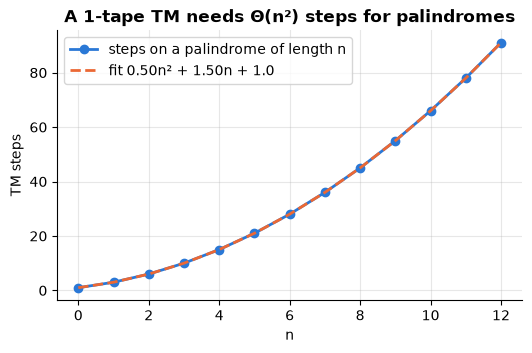

In [19]:
# Verify increment on every number 0..500
for n in range(501):
    assert increment.run(format(n, "b"))["output"] == format(n + 1, "b")
print("Binary increment is correct for n = 0..500")

# Palindrome checker over {0,1}: erase the first symbol, run to the end, compare with the last
palindrome = TuringMachine({
    ("q0", "0"): ("have0", "_", "R"), ("q0", "1"): ("have1", "_", "R"), ("q0", "_"): ("accept", "_", "R"),
    ("have0", "0"): ("have0", "0", "R"), ("have0", "1"): ("have0", "1", "R"), ("have0", "_"): ("check0", "_", "L"),
    ("have1", "0"): ("have1", "0", "R"), ("have1", "1"): ("have1", "1", "R"), ("have1", "_"): ("check1", "_", "L"),
    ("check0", "0"): ("back", "_", "L"), ("check0", "_"): ("accept", "_", "R"), ("check0", "1"): ("reject", "1", "R"),
    ("check1", "1"): ("back", "_", "L"), ("check1", "_"): ("accept", "_", "R"), ("check1", "0"): ("reject", "0", "R"),
    ("back", "0"): ("back", "0", "L"), ("back", "1"): ("back", "1", "L"), ("back", "_"): ("q0", "_", "R"),
}, start="q0")

steps_by_n = {}
for w in all_strings("01", 12):
    r = palindrome.run(w)
    assert (r["state"] == "accept") == (w == w[::-1]), w
    if w == w[::-1]:
        steps_by_n[len(w)] = max(steps_by_n.get(len(w), 0), r["steps"])
print("Palindrome TM is correct on all", 2 ** 13 - 1, "binary strings up to length 12")

ns = np.array(sorted(steps_by_n)); st = np.array([steps_by_n[n] for n in ns])
coef = np.polyfit(ns, st, 2)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ns, st, "o-", label="steps on a palindrome of length n")
ax.plot(ns, np.polyval(coef, ns), "--", label=f"fit {coef[0]:.2f}n² + {coef[1]:.2f}n + {coef[2]:.1f}")
ax.set_xlabel("n"); ax.set_ylabel("TM steps"); ax.set_title("A 1-tape TM needs Θ(n²) steps for palindromes")
ax.legend(); plt.show()

**What just happened?** The increment trace shows the head walking right to the blank, then turning `1`s into `0`s while it carries, until it finds a `0` (or a blank) to turn into `1`. The palindrome machine zig-zags across the tape once per pair of symbols, so its running time is quadratic: the fitted curve is almost exactly $\tfrac12 n^2$. This is optimal for a *single-tape* TM (a known lower bound); with two tapes, palindromes take $O(n)$ steps. Different machine models change running times by polynomial factors, which is why complexity classes such as **P** are defined "up to polynomials".

**Busy beavers: how long can a tiny machine run?** The **busy beaver** $BB(n)$ is the largest number of steps an $n$-state, 2-symbol TM can make *before halting*, starting on a blank tape. It grows faster than any computable function, so no program can compute it for all $n$. Known values: $BB(1) = 1$, $BB(2) = 6$, $BB(3) = 21$, $BB(4) = 107$, and $BB(5) = 47{,}176{,}870$, proved in 2024 by the online *bbchallenge* collaboration with a computer-checked proof in the Coq proof assistant. $BB(6)$ is known to be astronomically larger. Let us run the step champions for 2, 3 and 4 states.

In [20]:
def bb_machine(table):
    """table like 'A0:1RB A1:1LB ...'; H is the halting state."""
    delta = {}
    for item in table.split():
        lhs, rhs = item.split(":")
        delta[(lhs[0], lhs[1])] = ("halt" if rhs[2] == "H" else rhs[2], rhs[0], rhs[1])
    return TuringMachine(delta, start="A", blank="0")

champions = {2: "A0:1RB A1:1LB B0:1LA B1:1RH",
             3: "A0:1RB A1:1RH B0:1LB B1:0RC C0:1LC C1:1LA",
             4: "A0:1RB A1:1LB B0:1LA B1:0LC C0:1RH C1:1LD D0:1RD D1:0RA"}
rows = []
for n, table in champions.items():
    r = bb_machine(table).run("", max_steps=10_000)
    # The halting transition itself counts as a step in the standard definition
    rows.append({"states": n, "steps until halt": r["steps"], "ones left on tape": r["output"].count("1"),
                 "halted": r["halted"]})
df_bb = pd.DataFrame(rows)
assert list(df_bb["steps until halt"]) == [6, 21, 107]
df_bb

,states,steps until halt,ones left on tape,halted
0,2,6,4,True
1,3,21,5,True
2,4,107,13,True


**What just happened?** Our simulator reproduces the known step counts $BB(2) = 6$, $BB(3) = 21$ and $BB(4) = 107$ (the halting move counts as a step). Notice that the champion for *steps* is not always the champion for *ones*: the 3-state step champion leaves 5 ones, while a different 3-state machine leaves the maximum of 6 ones in only 14 steps. Running the 5-state champion would take 47 million steps, which is fine for a computer, but *proving* that no other 5-state machine runs longer took decades, because it means proving that thousands of other machines never halt. That is the halting problem in miniature.

---
## 10. Decidability and the halting problem

> **In plain English:** no program can look at every other program and always correctly predict whether it will finish or run forever.

**Definitions.**
- A language $L$ is **decidable** (recursive) if some TM **halts on every input** and accepts exactly the strings in $L$. That TM is a **decider**: it always answers yes or no.
- $L$ is **recognisable** (recursively enumerable, semi-decidable) if some TM accepts exactly the strings in $L$, but on strings *not* in $L$ it may run forever.
- $L$ is decidable **iff** both $L$ and its complement are recognisable.

**The halting problem.** $\text{HALT} = \{\langle P, x\rangle : \text{program } P \text{ halts on input } x\}$.

HALT is **recognisable**: just run $P$ on $x$ and say "yes" if it stops. But Turing proved in 1936 that it is **not decidable**.

**Proof (diagonalisation), in Python-flavoured pseudocode.** Suppose, for contradiction, someone gives us a perfect function `halts(program, input)` that always returns `True` or `False` correctly. Then we can write:

```python
def paradox(program):
    if halts(program, program):   # would `program` halt when given its own source?
        while True:               # ... then do the opposite: loop forever
            pass
    else:
        return "done"             # ... otherwise halt immediately
```

Now ask: does `paradox(paradox)` halt?
- If `halts(paradox, paradox)` is `True`, then `paradox(paradox)` loops forever, so the answer `True` was wrong.
- If it is `False`, then `paradox(paradox)` returns at once, so `False` was wrong.

Either way `halts` is wrong on at least one input, so no such function can exist. ∎

The trick is the same **diagonal argument** Cantor used to show that the real numbers are uncountable (see [`01_sets_relations_functions_and_proofs.ipynb`](01_sets_relations_functions_and_proofs.ipynb)). Let us make the diagonal concrete: list some programs as rows, inputs as columns, mark whether each program halts on each input, then build a program that disagrees with every row on the diagonal.

In [21]:
# Six small "programs" written as Python generators: every `yield` is one computation step.
def p0(n):                       # halts immediately
    return
    yield
def p1(n):                       # never halts
    while True:
        yield
def p2(n):                       # halts iff n is even
    while n % 2 == 1:
        yield
def p3(n):                       # Collatz walk from n+1 (always halted, in every case anyone has tried)
    m = n + 1
    while m != 1:
        m = m // 2 if m % 2 == 0 else 3 * m + 1
        yield
def p4(n):                       # halts iff n < 3
    while n >= 3:
        yield
def p5(n):                       # halts iff n is prime
    while n < 2 or any(n % d == 0 for d in range(2, int(n ** 0.5) + 1)):
        yield
programs = [p0, p1, p2, p3, p4, p5]

def halts_within(prog, n, budget=10_000):
    """Run prog(n) for at most `budget` steps. This is decidable, unlike unbounded halting."""
    for steps, _ in enumerate(prog(n)):
        if steps >= budget:
            return False
    return True

table = pd.DataFrame([[halts_within(p, i) for i in range(len(programs))] for p in programs],
                     index=[f"P{k}" for k in range(len(programs))],
                     columns=[f"input {i}" for i in range(len(programs))])
diagonal = [table.iloc[i, i] for i in range(len(programs))]
D = [not d for d in diagonal]                # the diagonal program does the OPPOSITE on input i
print("Halts? (budget 10,000 steps; for these programs we know the budget is a correct proxy)")
display(table.replace({True: "halts", False: "loops"}))
print("Diagonal entries P_i(i):", ["halts" if d else "loops" for d in diagonal])
print("Diagonal program D(i):  ", ["halts" if d else "loops" for d in D])
for k in range(len(programs)):
    assert table.iloc[k, k] != D[k]          # D disagrees with program k on input k
print("D differs from every listed program on at least one input, so D is not in the list.")

Halts? (budget 10,000 steps; for these programs we know the budget is a correct proxy)


,input 0,input 1,input 2,input 3,input 4,input 5
P0,halts,halts,halts,halts,halts,halts
P1,loops,loops,loops,loops,loops,loops
P2,halts,loops,halts,loops,halts,loops
P3,halts,halts,halts,halts,halts,halts
P4,halts,halts,halts,loops,loops,loops
P5,loops,loops,halts,halts,loops,halts


Diagonal entries P_i(i): ['halts', 'loops', 'halts', 'halts', 'loops', 'halts']
Diagonal program D(i):   ['loops', 'halts', 'loops', 'loops', 'halts', 'loops']
D differs from every listed program on at least one input, so D is not in the list.


**What just happened?** Whatever list of programs you write down, the "flip the diagonal" program $D$ differs from row $k$ in column $k$, so it is missing from the list. In the halting proof the list is *all programs*, and $D$ is `paradox`: it would be a program, so it must be in the list, which is the contradiction.

**Why you cannot dodge this with "just run it longer".** `halts_within` is perfectly decidable, but a finite budget can never prove "loops forever". Here is how much would follow from a perfect `halts`:
- **Goldbach's conjecture** (every even number > 2 is a sum of two primes) is open. A ten-line program that searches for a counterexample halts **iff** the conjecture is false. A perfect halting decider would settle it instantly.
- The **Collatz conjecture** (row `P3`) is also open: it has been checked by computer for every starting value beyond $2^{68} \approx 3 \times 10^{20}$, but there is no proof.

| Problem | Decidable? |
|---|---|
| Does DFA $M$ accept $w$? Is $L(M)$ empty? Are two DFAs equivalent? | Yes |
| Does CFG $G$ generate $w$? (CYK) Is $L(G)$ empty? | Yes |
| Is CFG $G$ ambiguous? Do two CFGs generate the same language? | **No** |
| Does TM / Python program $P$ halt on $x$? | **No** (recognisable only) |
| Does $P$ halt within $10^6$ steps? | Yes (just run it) |
| Does $P$ *never* halt on $x$? | **No**, and not even recognisable |

---
## 11. Rice's theorem and what it means for tools

> **In plain English:** any interesting question about what a program does cannot be answered perfectly for all programs, so real tools make trade-offs.

**Rice's theorem (1953), in plain words:** *every* non-trivial question about **what a program does** (its input/output behaviour, the language it recognises) is undecidable.
- "Non-trivial" means some programs have the property and some do not.
- "What a program does" means the property depends only on behaviour, not on the source text. "Does the file contain the word `while`?" is about text and is easy; "Does the program ever divide by zero?" is about behaviour and is undecidable.

**Proof idea (a reduction).** Suppose a tool could decide "does program $Q$ ever print `hello`?". Given any $\langle P, x\rangle$, build

```python
def Q(_):
    P(x)              # run P on x (this may never return)
    print("hello")
```

$Q$ prints `hello` **iff** $P$ halts on $x$. So the `hello`-detector would decide HALT, which is impossible. The same template works for any behavioural property.

**What this means for real tools.** A *perfect* bug detector, malware detector, termination checker, or AI-safety verifier that works on **every** program cannot exist. Real tools therefore give up one of three things:

| Strategy | What it gives up | Examples |
|---|---|---|
| **Sound but incomplete** (never misses a bug, sometimes raises false alarms) | precision | type checkers (mypy, Rust's borrow checker), abstract interpretation |
| **Complete but unsound** (every warning is real, but some bugs are missed) | coverage | testing, fuzzing, linters with heuristics, LLM code review |
| **Restrict the language** so the question becomes decidable | expressiveness | regular expressions without backreferences, SQL without recursion, total languages (Coq, Agda, Lean) |
| **Bounded checking** | guarantees beyond the bound | timeouts, step limits, bounded model checking |

> 🎓 **Exam / interview tip.** To show a problem undecidable, **reduce HALT to it**: show that a decider for your problem could be used to build a decider for HALT. Get the direction right: you reduce the *known-hard* problem *to* the new problem.

> ⚠️ **Common mistake.** "Undecidable" does not mean "we can never answer it for a specific program". It means *no single algorithm answers it correctly for all programs*. You can certainly prove that a particular loop terminates.

---
## 12. Complexity classes: a short recap

> **In plain English:** among problems computers can solve, some are fast, some seem to need huge amounts of time, and nobody knows exactly where the line is.

Decidability asks *can* it be solved; complexity asks *how fast*. Inside the decidable problems:

| Class | Meaning | Example |
|---|---|---|
| **P** | solvable in polynomial time | CFG membership (CYK $O(n^3)$), shortest paths, sorting |
| **NP** | a "yes" answer has a certificate checkable in polynomial time | SAT, Hamiltonian cycle, graph 3-colouring |
| **NP-complete** | in NP and every NP problem reduces to it | SAT (Cook–Levin, 1971), TSP decision version |
| **PSPACE** | solvable with polynomial memory | context-sensitive membership, generalised chess/Go on an $n \times n$ board |
| **EXPTIME** | solvable in exponential time | generalised chess (EXPTIME-complete) |
| **Decidable** | solvable at all | everything above |
| **RE \ decidable** | only semi-decidable | HALT |

$$\text{P} \subseteq \text{NP} \subseteq \text{PSPACE} \subseteq \text{EXPTIME} \subsetneq \text{decidable} \subsetneq \text{RE}$$

We know $\text{P} \ne \text{EXPTIME}$ (time hierarchy theorem), so at least one of the inclusions between them is strict, but whether $\text{P} = \text{NP}$ is still open (one of the Clay Millennium Prize problems, unsolved as of 2026). Reductions, NP-completeness proofs and coping strategies are the topic of [`advanced_algorithms/02_np_completeness_and_reductions.ipynb`](../../00_AI_Fundamentals/advanced_algorithms/02_np_completeness_and_reductions.ipynb).

---
## 13. How this connects to modern AI

> **In plain English:** grammars and automata are what force an LLM to output valid JSON, and the halting problem explains why AI safety cannot be proven by one checker.

**1. Grammar-constrained LLM decoding.** An LLM produces text one token at a time by sampling from a probability distribution over its vocabulary. If you need valid JSON, SQL or a function call, you can **mask** every token that would make the output impossible to complete under a grammar, then sample from what remains. Libraries such as llama.cpp (GBNF grammars), Outlines, XGrammar and the structured-output modes of hosted APIs and of vLLM do exactly this, compiling a JSON schema or grammar into an automaton (often a pushdown automaton). [`08_LLM/17_structured_outputs.ipynb`](../../08_LLM/17_structured_outputs.ipynb) shows the API side; here is the mechanism on a toy.

The toy setup:
- The "language model" is a fixed random table of next-token scores (a bigram model), so it knows nothing about syntax.
- The vocabulary has multi-character tokens, like real BPE vocabularies: `"(1"`, `"2)"`, `"+("`.
- The grammar is our arithmetic grammar (with `+` and `*` only). Its PDA reduces to a **counter** (bracket depth) plus a flag "an operand is expected next".
- A token is allowed if feeding its characters through the automaton never fails. `<eos>` is allowed only in an accepting configuration.

In [22]:
VOCAB = ["1", "2", "3", "+", "*", "(", ")", "(1", "2)", "+(", ")*", "<eos>"]

def step_char(state, ch):
    """Deterministic PDA for the expression grammar: state = (depth, expecting_operand)."""
    depth, expect = state
    if expect:                                    # we need a number or "("
        if ch in "123": return (depth, False)
        if ch == "(":   return (depth + 1, True)
        return None
    if ch in "+*":      return (depth, True)      # after an operand: an operator or ")"
    if ch == ")" and depth > 0: return (depth - 1, False)
    return None

def feed(state, token):
    for ch in token:
        state = step_char(state, ch)
        if state is None:
            return None
    return state

def allowed_tokens(state, steps_left):
    accepting = state == (0, False)
    mask = []
    for tok in VOCAB:
        if tok == "<eos>":
            mask.append(accepting)
            continue
        nxt = feed(state, tok)
        ok = nxt is not None
        if ok and steps_left <= nxt[0] + 2:       # near the length limit: only tokens that move towards closing
            ok = (nxt[0] + nxt[1]) < (state[0] + state[1]) or (nxt[0] <= state[0] and not nxt[1])
        mask.append(ok)
    return np.array(mask)

lm_rng = np.random.default_rng(0)
BIGRAM_LOGITS = lm_rng.normal(0, 1.5, size=(len(VOCAB) + 1, len(VOCAB)))   # row = previous token (+ BOS)

def sample(constrained, max_tokens=12, seed=0):
    r = np.random.default_rng(seed)
    out, prev, state = [], len(VOCAB), (0, True)
    for t in range(max_tokens):
        logits = BIGRAM_LOGITS[prev].copy()
        if constrained:
            logits[~allowed_tokens(state, max_tokens - t)] = -np.inf     # the grammar mask
        p = np.exp(logits - logits.max()); p /= p.sum()
        k = r.choice(len(VOCAB), p=p)
        if VOCAB[k] == "<eos>":
            break
        out.append(VOCAB[k]); prev = k
        if constrained:
            state = feed(state, VOCAB[k])
    return "".join(out)

def is_valid_expr(s):
    try:
        ExprParser(s).parse(); return len(s) > 0
    except SyntaxError:
        return False

results = {mode: [sample(mode == "constrained", seed=s) for s in range(200)]
           for mode in ["unconstrained", "constrained"]}
for mode, outs in results.items():
    n_ok = sum(is_valid_expr(s) for s in outs)
    print(f"{mode:13s}: {n_ok:3d}/200 valid   e.g. {outs[:4]}")
assert all(is_valid_expr(s) for s in results["constrained"])
print("\nEvery constrained sample parses and evaluates:", [(s, evaluate(ExprParser(s).parse()))
                                                         for s in results["constrained"][:3]])

unconstrained:   2/200 valid   e.g. ['(311(1', '(', '*1(132)2)*1*3(1+', '1+']
constrained  : 200/200 valid   e.g. ['(3+1)', '(2)*(1+((1)*2))', '3+(2)*2+((3)*2)', '1+((3+(2)*2))']

Every constrained sample parses and evaluates: [('(3+1)', 4.0), ('(2)*(1+((1)*2))', 6.0), ('3+(2)*2+((3)*2)', 13.0)]


**What just happened?** The same random "model" produced mostly invalid strings on its own, but **every** constrained sample is a valid expression, because the mask never lets the output leave the language. The model's preferences still decide *which* valid string comes out. Real systems precompute masks for vocabularies of 100,000+ tokens and handle full JSON-schema grammars, but the principle is exactly this: an automaton (here a one-counter PDA) runs alongside the decoder. A length budget matters too: our mask forces the expression to close as the token limit approaches, otherwise a constrained model can be "stuck" mid-expression when it runs out of tokens.

**2. Tokenizers and lexers are automata.** A lexer is a DFA built from regular expressions (Section 6 used one). A BPE tokenizer's vocabulary is usually stored as a trie, which is a DFA over characters, and many tokenizers apply a regex pre-tokenisation step first.

**3. Probabilistic grammars in NLP.** A **probabilistic CFG (PCFG)** attaches a probability to each rule. CYK with *max* instead of *or* (the Viterbi version) returns the most probable parse tree, which resolves ambiguity by statistics instead of by layered rules. This is the classical constituency parser used in [`07_NLP/10_advanced_nlp_tasks.ipynb`](../../07_NLP/10_advanced_nlp_tasks.ipynb).

**4. Limits of verification.** Rice's theorem is why AI-safety and code-security work relies on testing, red-teaming, sandboxing, monitoring and restricted action spaces rather than a single "prove this agent is safe" checker (see [`00_AI_Fundamentals/05_robustness_and_safety.ipynb`](../../00_AI_Fundamentals/05_robustness_and_safety.ipynb) and [`08_LLM/16_llm_security.ipynb`](../../08_LLM/16_llm_security.ipynb)).

**5. What can transformers compute?** Active research studies which formal languages fixed-size transformers recognise; for example, some bracket languages (Dyck languages) are hard for them to learn at long lengths. The Chomsky hierarchy is the yardstick that research uses.

---
## 14. Recap

- A **CFG** $(V, \Sigma, R, S)$ generates strings by replacing variables; a **parse tree** records which rules were used. CFGs describe nesting, which regular expressions cannot.
- A grammar is **ambiguous** if one string has two parse trees. Fix expression ambiguity with one variable per precedence level; deciding ambiguity in general is undecidable.
- **Chomsky normal form** ($A \to BC$, $A \to a$, $S \to \varepsilon$) exists for every CFG; the conversion is START, TERM, BIN, DEL, UNIT.
- **CYK** decides membership for any CFG in **$O(n^3 |R|)$** time by dynamic programming over substrings.
- **Recursive descent** parses LL(1) grammars in **$O(n)$**; left recursion must be rewritten as loops; left recursion gives left associativity.
- **PDA = finite automaton + stack**; CFLs are exactly the languages of nondeterministic PDAs, and nondeterministic PDAs are strictly stronger than deterministic ones.
- The **Chomsky hierarchy**: regular ⊊ context-free ⊊ context-sensitive ⊊ decidable ⊊ RE.
- A **Turing machine** (finite control + infinite read/write tape) captures every algorithm (Church–Turing thesis).
- **HALT is undecidable** (diagonal argument); **Rice's theorem** extends this to every non-trivial behavioural property, so practical tools are sound-but-incomplete, unsound, restricted or bounded.
- **Grammar-constrained decoding** runs an automaton next to an LLM to guarantee syntactically valid output.

---
## Practice problems

**1. (Easy, conceptual)** Why can a PDA recognise balanced brackets when no DFA can? What exactly does the stack store?

<details><summary>Show solution</summary>

A DFA has a fixed number $k$ of states, so after reading `(` $k+1$ times it must be in a state it already visited after some smaller number $j$ of `(`. From that state, it cannot tell whether $k+1$ or $j$ closing brackets are needed, so it accepts or rejects one of $(^{j})^{k+1}$ and $(^{k+1})^{k+1}$ wrongly. (That is the pumping-lemma argument.) A PDA pushes one symbol per unmatched opening bracket, so the stack height *is* the current nesting depth, which can grow without limit; with several bracket types the stack also stores *which* bracket must close next.

</details>

**2. (Easy, coding)** Write a CFG for $\{a^nb^{2n} : n \ge 0\}$ and test it with `to_cnf` + `cyk` against an oracle on all strings up to length 9.

<details><summary>Show solution</summary>

```python
G = {"S": [("a", "S", "b", "b"), ()]}          # S -> a S b b | eps
cnf, s0 = to_cnf(G, "S")
oracle = lambda w: (n := w.count("a")) * 3 == len(w) and w == "a" * n + "b" * (2 * n)
assert all(cyk(cnf, s0, w) == oracle(w) for w in all_strings("ab", 9))
print("correct on all strings up to length 9")
```
Each application of $S \to aSbb$ adds one `a` on the left and two `b`s on the right, so after $n$ steps and $S \to \varepsilon$ we get $a^nb^{2n}$.

</details>

**3. (Medium)** How many parse trees does `aaaa` have under $S \to SS \mid a$? Check with `all_parse_trees`, find the general formula for $a^n$, and give an unambiguous grammar for the same language.

<details><summary>Show solution</summary>

```python
G = {"S": [("S", "S"), ("a",)]}
print([len(all_parse_trees(G, "S", list("a" * n))) for n in range(1, 8)])   # [1, 1, 2, 5, 14, 42, 132]
```
A parse tree of $a^n$ under $S \to SS \mid a$ is a full binary tree with $n$ leaves, and there are $C_{n-1}$ of them (Catalan numbers). For `aaaa`: $C_3 = 5$ trees. So the grammar is ambiguous; $S \to aS \mid a$ generates the same language unambiguously.

</details>

**4. (Medium, coding)** Extend the recursive-descent parser with the modulo operator `%` at the same precedence as `*` and `/`. Check against Python on a few expressions.

<details><summary>Show solution</summary>

```python
class ModParser(ExprParser):
    def term(self):                                   # term := unary { (*|/|%) unary }
        node = self.unary()
        while self.peek()[1] in ("*", "/", "%"):
            op = self.eat()
            node = (op, node, self.unary())
        return node

def evaluate_mod(node):
    tag = node[0]
    if tag == "num": return node[1]
    if tag == "neg": return -evaluate_mod(node[1])
    a, b = evaluate_mod(node[1]), evaluate_mod(node[2])
    if tag == "%": return a % b
    return evaluate((tag, ("num", a), ("num", b)))     # reuse the other operators

for s in ["7 % 3", "2 + 7 % 3 * 2", "20 % 7 % 4", "-7 % 3"]:
    print(s, "=", evaluate_mod(ModParser(s).parse()), "| Python:", eval(s))
```
The tokenizer already returns `%` as an operator; only the `term` level changes. `%` gets the same precedence and left associativity as `*` and `/`, which matches Python. (`-7 % 3` is `2` in both, because unary minus binds tighter than `%`.)

</details>

**5. (Medium, coding)** Build a PDA (with our `PDA` class) for $\{w \in \{a,b\}^* : w \text{ has equally many a's and b's}\}$ and test it on all strings up to length 10.

<details><summary>Show solution</summary>

```python
# Stack holds the "surplus": A's if more a's seen so far, B's if more b's.
delta = {("start", "", ""): [("q", "$")], ("q", "", "$"): [("accept", "")]}
delta[("q", "a", "$")] = [("q", "A$")]; delta[("q", "b", "$")] = [("q", "B$")]
delta[("q", "a", "A")] = [("q", "AA")]; delta[("q", "b", "B")] = [("q", "BB")]
delta[("q", "a", "B")] = [("q", "")];   delta[("q", "b", "A")] = [("q", "")]
pda_eq = PDA(delta, "start", {"accept"})
assert all(pda_eq.accepts(w) == (w.count("a") == w.count("b")) for w in all_strings("ab", 10))
print("correct on all 2047 strings up to length 10")
```
The language $\{w : \#_a(w) = \#_b(w)\}$ is context-free but not regular. A CFG for it: $S \to aSbS \mid bSaS \mid \varepsilon$.

</details>

**6. (Hard, coding)** Write a Turing machine for unary addition: input `1^m+1^n`, output `1^(m+n)`. How many steps does it take?

<details><summary>Show solution</summary>

```python
# Input 1^m + 1^n (e.g. "111+11"). Replace "+" by "1", then erase the last "1".
add = TuringMachine({
    ("scan", "1"): ("scan", "1", "R"), ("scan", "+"): ("scan", "1", "R"),
    ("scan", "_"): ("erase", "_", "L"),
    ("erase", "1"): ("halt", "_", "L"),
}, start="scan")
for m in range(6):
    for n in range(6):
        assert add.run("1" * m + "+" + "1" * n)["output"] == "1" * (m + n)
print(add.run("111+11")["output"])     # 11111
```
The machine reads the $m + n + 1$ input symbols, one more step on the blank, and one step to erase: $m + n + 3$ steps, so $O(m + n)$.

</details>

**7. (Hard, proof)** Prove that it is undecidable whether a Python function `f` ever returns the value `42` on input `0`.

<details><summary>Show solution</summary>

Reduce HALT to it. Suppose `returns42(f)` decides the property. Given any program `P` and input `x`, build

```python
def f(_):
    P(x)          # may never return
    return 42
```

`f(0)` returns 42 **iff** `P` halts on `x`. So `halts(P, x) = returns42(f)` would decide HALT, which is impossible. Hence `returns42` cannot exist. (This is one instance of Rice's theorem: "returns 42 on input 0" is a non-trivial property of the program's behaviour.)

</details>

**8. (Hard, exam-style)** Classify each language into the smallest class of the Chomsky hierarchy, with a one-line reason: $(ab)^*$; $\{a^nb^n\}$; $\{a^nb^nc^n\}$; $\{ww : w \in \{a,b\}^*\}$; the set of programs that halt on empty input; the set of programs that never halt on empty input.

<details><summary>Show solution</summary>

| Language | Smallest class | Why |
|---|---|---|
| $(ab)^*$ | regular | a 2-state DFA |
| $\{a^nb^n\}$ | context-free, not regular | pumping lemma for regular languages |
| $\{a^nb^nc^n\}$ | context-sensitive, not context-free | pumping lemma for CFLs (Section 8) |
| $\{ww : w \in \{a,b\}^*\}$ | context-sensitive, not context-free | pumping lemma for CFLs with $a^pb^pa^pb^p$; note $\{ww^R\}$ *is* context-free |
| $\{\langle P\rangle : P \text{ halts on empty input}\}$ | RE, not decidable | halting problem |
| $\{\langle P\rangle : P \text{ never halts on empty input}\}$ | not even RE | complement of an RE-but-undecidable language |

</details>

---
## Further reading
- Michael Sipser, *Introduction to the Theory of Computation*, 3rd ed.: Ch. 2 (CFGs, PDAs, CNF, pumping lemma), Ch. 3 (Turing machines), Ch. 4 (decidability, the halting problem), Ch. 5 (reductions, Rice's theorem), Ch. 7 (P and NP).
- Hopcroft, Motwani and Ullman, *Introduction to Automata Theory, Languages, and Computation*, 3rd ed.: Ch. 5 to 7 (CFGs, PDAs, CYK) and Ch. 8 to 9 (TMs, undecidability).
- Aho, Lam, Sethi and Ullman, *Compilers: Principles, Techniques, and Tools* ("the Dragon Book"), 2nd ed., Ch. 4 (top-down and bottom-up parsing).
- Jurafsky and Martin, *Speech and Language Processing* (3rd ed. draft, free online at https://web.stanford.edu/~jurafsky/slp3/): the chapters on constituency grammars, CKY parsing and PCFGs.
- Free: MIT OpenCourseWare 18.404J *Theory of Computation* (Sipser's own lectures, video and notes).

## Next notebook
Continue with numerical methods: [`../09_numerical_methods.ipynb`](../09_numerical_methods.ipynb) (root finding, interpolation, numerical differentiation and integration, ODE solvers).